# Unsupervised Clustering of Motor-Imagery EEG (BCI Competition IV 2a)
**Goal:** cluster 4-class motor-imagery trials (left hand, right hand, feet, tongue) *without labels* using Riemannian-geometry features. Labels are used only for evaluation.

| Step | Section |
|---|---|
| Load + epoch GDF files | 2-3 |
| Riemannian features (covariance → tangent space) | 4 |
| Algorithms + metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz, ARI, NMI) | 5, 7 |
| Elbow curve (K-Means) and dendrograms (hierarchical) | 6, 8 |
| PCA and t-SNE cluster visualisations | 9 |
| Extra diagnostics, evaluation session, all-subject summary | 10-12 |

**Required algorithms:** K-Means and Agglomerative (Ward). Riemannian K-Means and the other linkages are extensions.

## 1. Imports and configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy.io import loadmat
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import squareform, pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score, silhouette_score,
                             silhouette_samples, davies_bouldin_score, calinski_harabasz_score)
from sklearn.preprocessing import StandardScaler
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from pyriemann.clustering import Kmeans as RiemannKmeans
try:   # newer pyriemann
    from pyriemann.geometry.mean import mean_covariance
    from pyriemann.geometry.base import invsqrtm
    from pyriemann.geometry.distance import pairwise_distance
except ImportError:   # older pyriemann
    from pyriemann.utils.mean import mean_covariance
    from pyriemann.utils.base import invsqrtm
    from pyriemann.utils.distance import pairwise_distance

mne.set_log_level("WARNING")

DATA_DIR = "../datasets"                 # A01T.gdf ... A09T.gdf, A01E.gdf ...
LABELS_DIR = "../datasets/true_labels"   # A01E.mat ... (labels of the evaluation sessions only)
FIG_DIR = "../results"                   # figures are saved here
N_CLASSES = 4
K_RANGE = range(2, 11)                   # k values for the elbow curve
FMIN, FMAX = 8.0, 30.0                   # mu + beta band (Hz)
TMIN, TMAX = 0.5, 2.5                    # window after the cue (s)
METRICS = ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz", "ARI", "NMI"]

## 2. Loading and epoching
Reads a GDF file, keeps the 22 EEG channels (drops EOG), band-pass filters, epochs around the cue and removes artifact trials (event `1023`).
- Training files (`A0xT`): cue events `769-772` carry the class labels.
- Evaluation files (`A0xE`): all cues are `783`; labels come from the separate `.mat` file.

In [2]:
TRAIN_EVENTS = {"769": 1, "770": 2, "771": 3, "772": 4}
CLASS_NAMES = {1: "left", 2: "right", 3: "feet", 4: "tongue"}


def save_fig(fig, name):
    # Save a figure into FIG_DIR (created on demand)
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")


def load_epochs(gdf_path, mat_path=None):
    # Returns X (trials, 22, samples) in microvolts and y (labels 1-4)
    raw = mne.io.read_raw_gdf(gdf_path, preload=True)
    raw.pick(picks="eeg")                       # drops the 3 EOG channels
    raw.filter(FMIN, FMAX)
    sfreq = raw.info["sfreq"]

    if mat_path is None:                        # training session
        events, _ = mne.events_from_annotations(raw, event_id=TRAIN_EVENTS)
        y_all = events[:, 2].copy()
    else:                                       # evaluation session
        events, _ = mne.events_from_annotations(raw, event_id={"783": 5})
        y_all = loadmat(mat_path)["classlabel"].ravel().astype(int)
        assert len(y_all) == len(events), "label count does not match number of trials"

    ep = mne.Epochs(raw, events, event_id=None, tmin=TMIN, tmax=TMAX, baseline=None, preload=True)
    y_all = y_all[ep.selection]

    # Drop trials whose epoch window overlaps an artifact annotation ('1023')
    ann = raw.annotations
    art = [(o, o + d) for o, d, desc in zip(ann.onset, ann.duration, ann.description) if desc == "1023"]
    t_cue = ep.events[:, 0] / sfreq
    bad = np.zeros(len(ep), dtype=bool)
    for a0, a1 in art:
        bad |= (a0 <= t_cue + TMAX) & (a1 >= t_cue + TMIN)

    return ep.get_data()[~bad] * 1e6, y_all[~bad]

## 3. Load subject 1 (training session)

In [3]:
X, y = load_epochs(f"{DATA_DIR}/A01T.gdf")
print("X:", X.shape, "| y:", y.shape)
print({CLASS_NAMES[k]: int((y == k).sum()) for k in sorted(CLASS_NAMES)})

c:\Users\akila\AppData\Local\Programs\Python\Python314\Lib\contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


X: (273, 25, 501) | y: (273,)
{'left': 69, 'right': 69, 'feet': 68, 'tongue': 67}


## 4. Riemannian features
Covariance matrix per trial (OAS shrinkage) → recentre by the subject's Riemannian mean → tangent space → standardise → PCA (95% variance). No labels are used.

In [4]:
def riemannian_features(X):
    # Returns (SPD covariance matrices, PCA-reduced tangent-space features)
    covs = Covariances(estimator="oas").fit_transform(X)
    ref_inv_sqrt = invsqrtm(mean_covariance(covs, metric="riemann"))
    covs = np.array([ref_inv_sqrt @ C @ ref_inv_sqrt for C in covs])   # per-subject recentring
    ts = TangentSpace(metric="riemann").fit_transform(covs)
    ts = StandardScaler().fit_transform(ts)
    feats = PCA(n_components=0.95, svd_solver="full").fit_transform(ts)
    return covs, feats

In [5]:
covs, feats = riemannian_features(X)
print("covariances:", covs.shape, "| tangent + PCA features:", feats.shape)

covariances: (273, 25, 25) | tangent + PCA features: (273, 158)


## 5. Algorithms and metrics
- `fit_algorithms` fits every algorithm and returns cluster labels (no ground truth used).
- `evaluate_all` reports internal metrics (**Silhouette** ↑, **Davies-Bouldin** ↓, **Calinski-Harabasz** ↑) plus external metrics against the true classes (**ARI**, **NMI** ↑).
- Ward needs Euclidean distances, so it runs on tangent-space features. Complete / average / single linkage use the Riemannian distance matrix.

In [6]:
def build_linkages(covs, feats):
    # Hierarchical linkage matrices (and the distances they were built on)
    D = pairwise_distance(covs, metric="riemann")
    D = (D + D.T) / 2
    np.fill_diagonal(D, 0)
    cond = squareform(D, checks=False)
    links = {"ward (tangent)": (linkage(feats, "ward"), pdist(feats))}
    for m in ["complete", "average", "single"]:
        links[f"{m} (Riemann)"] = (linkage(cond, m), cond)
    return links


def fit_algorithms(covs, feats, k=N_CLASSES):
    # Returns {name: labels} and the linkage matrices
    labels = {"KMeans": KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(feats),
              "Riemannian KMeans": RiemannKmeans(n_clusters=k, metric="riemann", n_init=5,
                                                 random_state=0).fit_predict(covs)}
    links = build_linkages(covs, feats)
    for name, (Z, _) in links.items():
        labels[f"Agglo {name}"] = fcluster(Z, k, "maxclust")
    return labels, links


def evaluate_all(labels_dict, feats, y):
    # Internal + external metrics for every algorithm
    rows = {}
    for name, lab in labels_dict.items():
        ok = len(np.unique(lab)) > 1
        rows[name] = dict(
            Silhouette=silhouette_score(feats, lab) if ok else np.nan,
            Davies_Bouldin=davies_bouldin_score(feats, lab) if ok else np.nan,
            Calinski_Harabasz=calinski_harabasz_score(feats, lab) if ok else np.nan,
            ARI=adjusted_rand_score(y, lab),
            NMI=normalized_mutual_info_score(y, lab))
    return pd.DataFrame(rows).T

## 6. K-Means elbow curve

In [7]:
def plot_elbow(feats, title=""):
    inertia, sil = [], []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(feats)
        inertia.append(km.inertia_)
        sil.append(silhouette_score(feats, km.labels_))
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
    ax[0].plot(list(K_RANGE), inertia, "o-"); ax[0].set(xlabel="k", ylabel="Inertia", title="Elbow curve")
    ax[1].plot(list(K_RANGE), sil, "o-"); ax[1].set(xlabel="k", ylabel="Silhouette", title="Silhouette vs k")
    fig.suptitle(title); fig.tight_layout(); save_fig(fig, "kmeans_elbow"); plt.show()

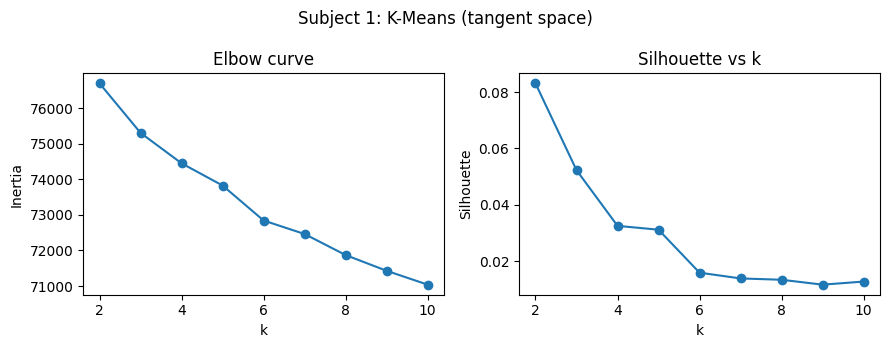

In [8]:
plot_elbow(feats, "Subject 1: K-Means (tangent space)")

## 7. Fit all algorithms and report metrics

In [9]:
labels_dict, links = fit_algorithms(covs, feats)
results = evaluate_all(labels_dict, feats, y)
results.round(3)

,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI
KMeans,0.032,4.755,11.965,0.347,0.434
Riemannian KMeans,0.023,5.150,11.870,0.317,0.392
Agglo ward (tangent),0.028,5.054,11.141,0.342,0.413
Agglo complete (Riemann),0.043,4.306,11.022,0.349,0.416
Agglo average (Riemann),0.067,2.314,10.226,0.357,0.424
Agglo single (Riemann),0.099,0.765,1.744,0.000,0.021


## 8. Dendrograms (hierarchical clustering)

In [10]:
def plot_dendrograms(links, title=""):
    fig, axes = plt.subplots(1, len(links), figsize=(4.5 * len(links), 4))
    for ax, (name, (Z, dist)) in zip(axes, links.items()):
        dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, no_labels=True)   # last 30 merges only
        ax.set_title(f"{name}\ncophenetic r = {cophenet(Z, dist)[0]:.2f}", fontsize=10)
    fig.suptitle(title); fig.tight_layout(); save_fig(fig, "dendrograms"); plt.show()

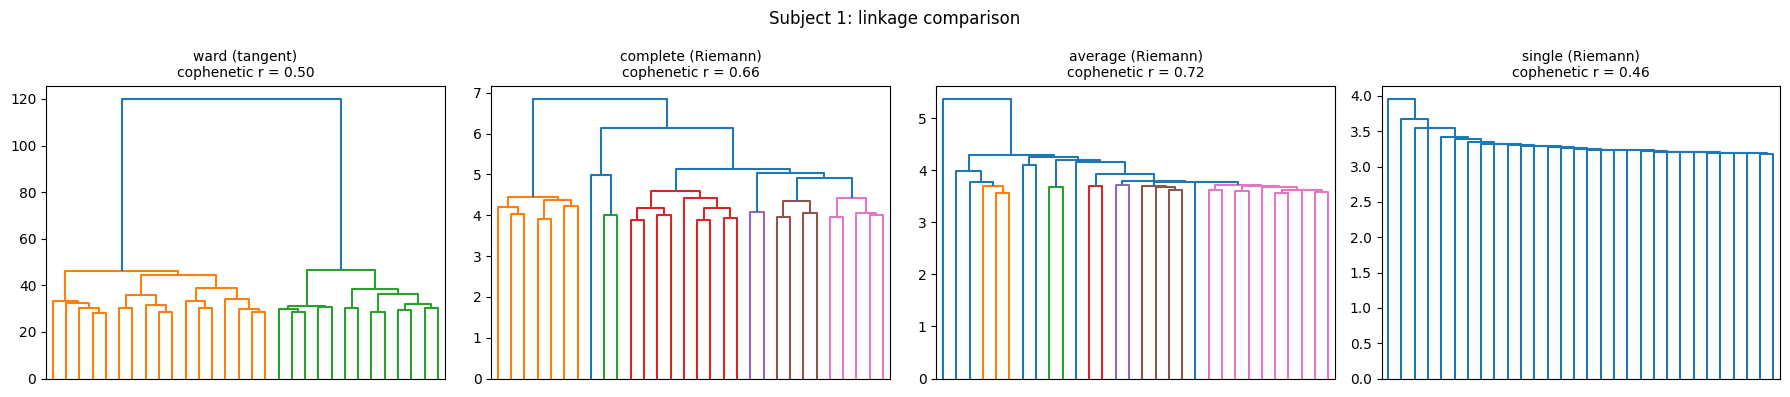

In [11]:
plot_dendrograms(links, "Subject 1: linkage comparison")

## 9. Cluster visualisation: PCA and t-SNE
Every algorithm is plotted in a 2D PCA projection and in a t-SNE projection, next to the true classes. (t-SNE preserves local structure only; distances between far-apart groups are not meaningful.)

In [12]:
def plot_embedding(emb, y, labels_dict, name, fname):
    panels = [("True classes", y)] + list(labels_dict.items())
    ncols = 4
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.8 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (title, lab) in zip(axes, panels):
        ax.scatter(emb[:, 0], emb[:, 1], c=lab, cmap="tab10", s=14, alpha=0.8)
        ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    for ax in axes[len(panels):]:
        ax.axis("off")
    fig.suptitle(f"{name} projection"); fig.tight_layout(); save_fig(fig, fname); plt.show()

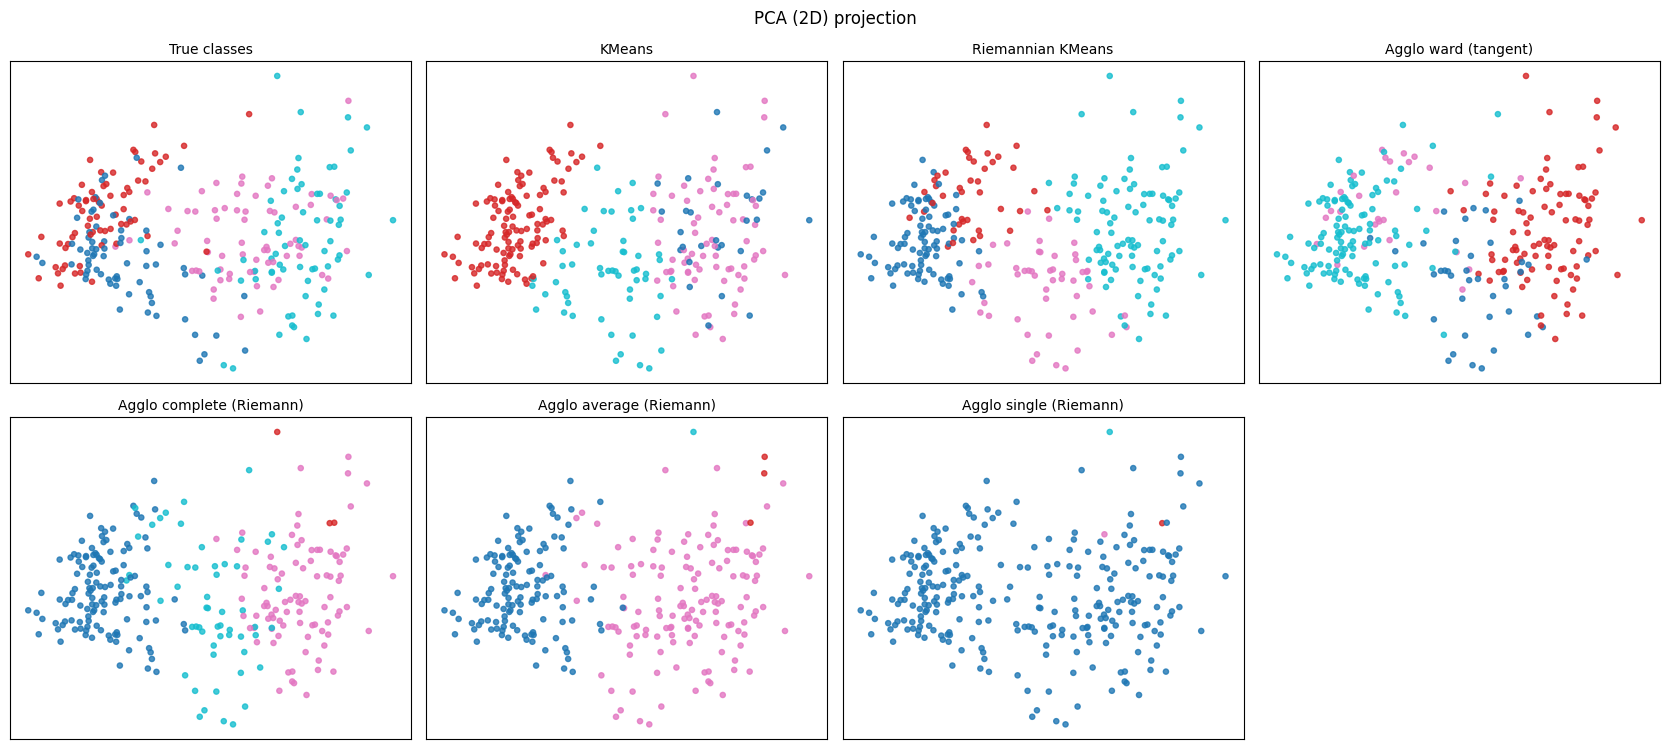

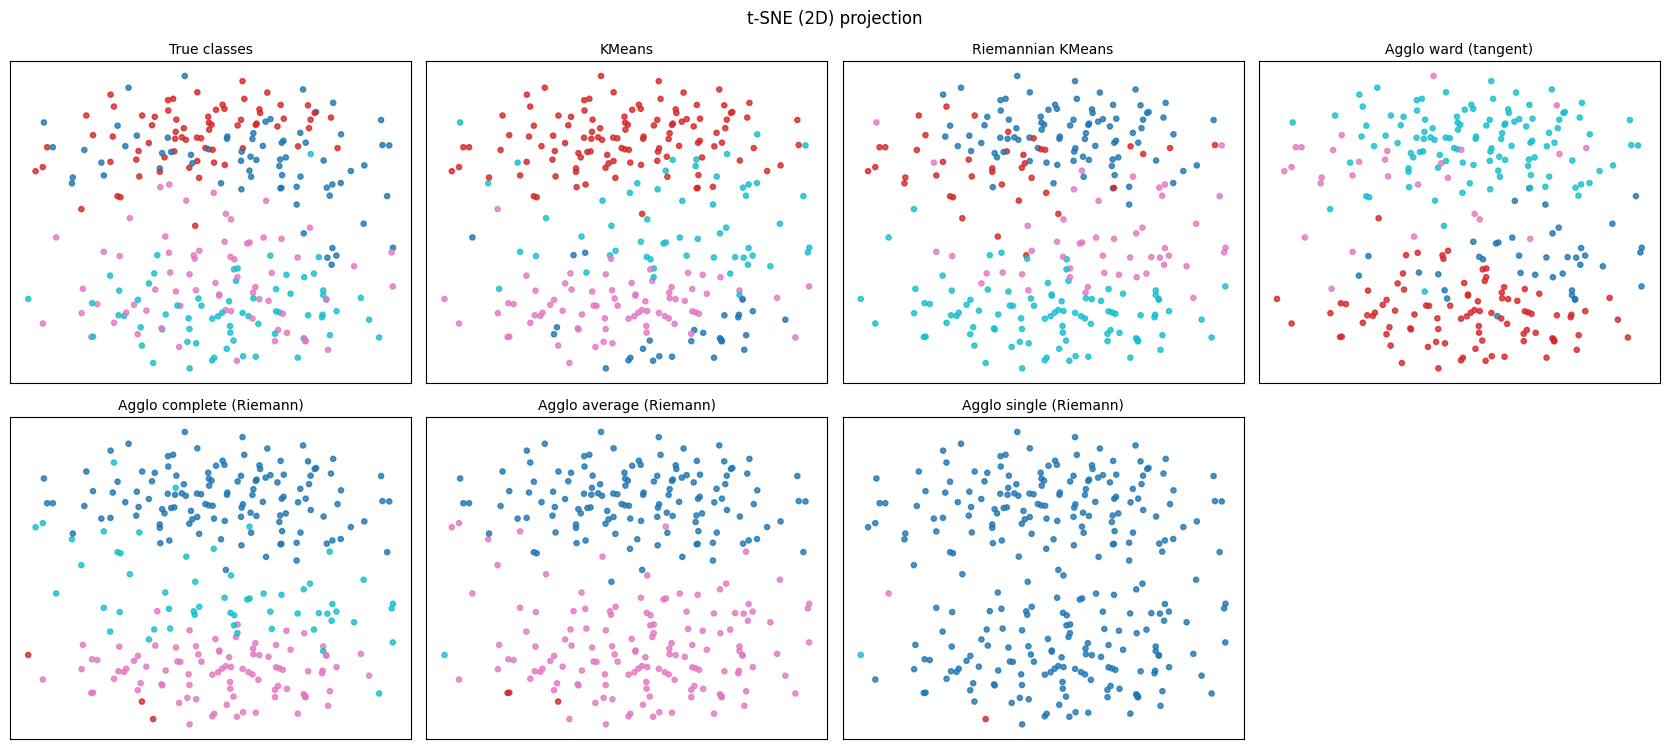

In [13]:
emb_pca = PCA(n_components=2).fit_transform(feats)
emb_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(feats)
plot_embedding(emb_pca, y, labels_dict, "PCA (2D)", "clusters_pca")
plot_embedding(emb_tsne, y, labels_dict, "t-SNE (2D)", "clusters_tsne")

## 10. Extra diagnostics (K-Means)
Silhouette plot (per-trial cohesion) and a contingency heatmap (true class vs cluster) show which classes get merged.

In [14]:
def plot_silhouette(feats, labels):
    sil = silhouette_samples(feats, labels)
    fig, ax = plt.subplots(figsize=(6, 4))
    y_low = 0
    for c in np.unique(labels):
        vals = np.sort(sil[labels == c])
        ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, alpha=0.8, label=f"cluster {c}")
        y_low += len(vals) + 5
    ax.axvline(sil.mean(), color="r", ls="--", label=f"mean = {sil.mean():.3f}")
    ax.set(xlabel="Silhouette value", ylabel="Trials (sorted within cluster)", title="Silhouette plot")
    ax.legend(); fig.tight_layout(); save_fig(fig, "silhouette_plot"); plt.show()


def plot_contingency(y, labels):
    ct = pd.crosstab(pd.Series(y).map(CLASS_NAMES).rename("true class"), pd.Series(labels).rename("cluster"))
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(ct.values, cmap="Blues")
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha="center", va="center")
    ax.set(xlabel="cluster", ylabel="true class", title="Cluster vs class (K-Means)")
    fig.colorbar(im); fig.tight_layout(); save_fig(fig, "contingency_kmeans"); plt.show()

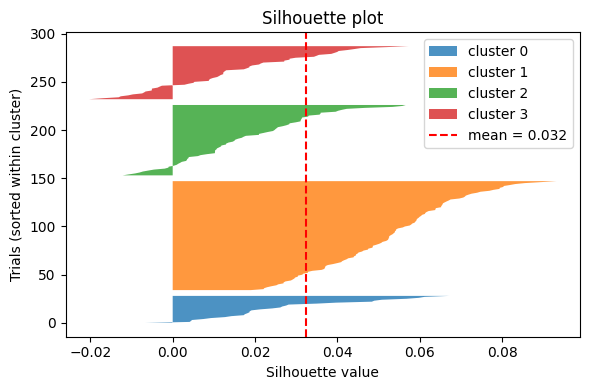

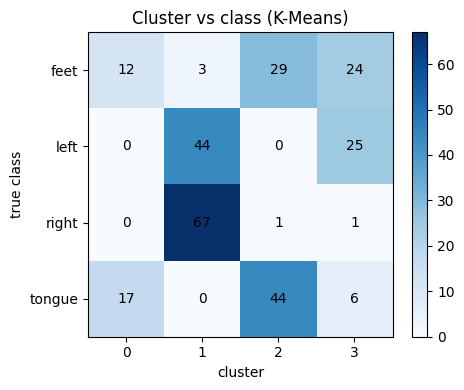

In [15]:
plot_silhouette(feats, labels_dict["KMeans"])
plot_contingency(y, labels_dict["KMeans"])